# Red Neuronal: MLP Regressor

## Introducción

En este notebook se desarrolla una red neuronal artificial multicapa: **Multilayer Perceptron (MLP)** para resolver un problema de regresión supervisada.

La variable objetivo será `log_bought`, definida como `log1p(bought_in_last_month)`. El uso de la transformación logarítmica permite trabajar con una escala menos asimétrica y reduce la influencia desproporcionada de los valores más elevados.

Se utilizará `MLPRegressor` de scikit-learn. El experimento es autónomo y conserva la metodología común del laboratorio para que sus resultados puedan compararse con los demás modelos.

## Objetivos del modelo

- Construir una red neuronal multicapa para predecir `log_bought`.
- Aplicar escalado a las variables numéricas y codificación One-Hot a `buy_box_status`.
- Evitar fuga de información mediante un `Pipeline` y un `ColumnTransformer`.
- Seleccionar hiperparámetros sin utilizar el conjunto de prueba.
- Evaluar el modelo final en escala logarítmica y en la escala aproximada de compras.

## Carga de librerías

Se emplean pandas y NumPy para manipulación de datos; Matplotlib y Seaborn para visualización; y scikit-learn para el preprocesamiento, la red neuronal, la búsqueda de hiperparámetros y las métricas. `joblib` permite guardar el pipeline completo.

In [1]:
import json
import time
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import (
    train_test_split,
    RandomizedSearchCV,
    StratifiedKFold
)
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    mean_squared_log_error
)

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")

print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


## Configuración inicial

Se fija la semilla aleatoria en 0 para favorecer la reproducibilidad. Se definen las rutas de entrada y salida.

Para comparar modelos de manera justa, se intentará reutilizar el archivo `split_indices.json` generado por el modelo de Random Forest. Si todavía no existe, se crearán las particiones con la misma semilla y proporciones, y se exportarán para que los otros experimentos puedan reutilizarlas. La igualdad exacta de particiones solo queda garantizada si todos los notebooks leen el mismo archivo.

In [ ]:
RANDOM_STATE = 0

DATASET_FILENAME = "dataset_v4.csv"
TARGET = "log_bought"
STRATIFY_COLUMN = "bought_cat"

RESULTS_DIR = Path("Models_Results") / "mlp"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

DATA_CANDIDATES = [
    Path(DATASET_FILENAME),
    Path("Limpieza de datos") / DATASET_FILENAME,
    Path("/content") / DATASET_FILENAME,
    Path("/content/Limpieza de datos") / DATASET_FILENAME,
    Path("../Limpieza de datos") / DATASET_FILENAME,

]

SPLIT_CANDIDATES = [
    Path("results/random_forest/split_indices.json"),
    Path("../Models_Results/random_forest/split_indices.json"),
    Path("results_random_forest/split_indices.json"),
    Path("Modelos entrenados/results/random_forest/split_indices.json"),
    Path("split_indices.json"),
]

print("Directorio de trabajo:", Path.cwd())
print("Directorio de resultados:", RESULTS_DIR.resolve())

Directorio de trabajo: c:\Users\Juan Mona\Documents\Repositories\ProductScope-ML\Modelos entrenados
Directorio de resultados: C:\Users\Juan Mona\Documents\Repositories\ProductScope-ML\Modelos entrenados\Models_Results\mlp


## Carga de datos

Se carga la variante v4, que contiene 31.202 registros según la documentación del proyecto. Si el archivo no está disponible, usar el archivo ubicado en el repositorio y colocarlo en el directorio de trabajo `content` en colab o en `Limpieza de datos/`.

In [ ]:
DATA_PATH = next((p for p in DATA_CANDIDATES if p.exists()), None)



df = pd.read_csv(DATA_PATH)

print("Archivo:", DATA_PATH)
print("Dimensiones:", df.shape)
display(df.head())

Archivo: ..\Limpieza de datos\dataset_v4.csv
Dimensiones: (31202, 18)


,Rating,Number_of_reviews,has_discount,is_best_seller_flag,is_sponsored_flag,has_coupon,buy_box_status,is_free_delivery,title_word_count,has_sustainability_badge,bought_in_last_month,bought_cat,current_price,is_price_outlier,log_price,log_reviews,log_bought,log_title_words
0,4.6,375.0,1,0,1,1,add_to_cart,0,30,1,350.0,201-500,89.68,0,4.507337,5.929589,5.860786,3.433987
1,4.3,2457.0,1,0,1,0,add_to_cart,0,34,0,6500.0,>500,9.99,0,2.396986,7.807103,8.779711,3.555348
2,4.6,3044.0,1,0,1,0,add_to_cart,0,29,0,2500.0,>500,314.00,1,5.752573,8.021256,7.824446,3.401197
3,4.6,35882.0,0,1,0,0,unknown,0,24,0,15000.0,>500,71.89,0,4.288951,10.488019,9.615872,3.218876
4,4.8,28988.0,0,0,0,0,unknown,0,24,0,15000.0,>500,71.89,0,4.288951,10.274672,9.615872,3.218876


## Exploración y validación

Antes del entrenamiento se comprueban las columnas necesarias, los tipos de datos, los valores ausentes y la disponibilidad del objetivo y de la variable auxiliar de estratificación.

In [30]:
print("Información general:")
display(df.info())

print("\\nValores ausentes por columna:")
display(df.isna().sum().sort_values(ascending=False).to_frame("n_missing"))

print("\\nEstadísticos del objetivo:")
display(df[TARGET].describe())

required_columns = [
    "Rating", "log_reviews", "log_price", "log_title_words",
    "has_discount", "is_best_seller_flag", "is_sponsored_flag",
    "has_coupon", "is_free_delivery", "is_price_outlier",
    "has_sustainability_badge", "buy_box_status",
    TARGET, STRATIFY_COLUMN
]

missing_columns = [c for c in required_columns if c not in df.columns]
if missing_columns:
    raise ValueError(f"Faltan columnas requeridas: {missing_columns}")

if df[required_columns].isna().any().any():
    missing = df[required_columns].isna().sum()
    raise ValueError(
        "Se encontraron valores ausentes en columnas necesarias. "
        f"Revisar antes de entrenar:\\n{missing[missing > 0]}"
    )

if not np.isfinite(df[TARGET].to_numpy(dtype=float)).all():
    raise ValueError("El objetivo contiene valores no finitos.")

print(f"\\nValidación superada: {len(df):,} filas disponibles.")

Información general:
<class 'pandas.DataFrame'>
RangeIndex: 31202 entries, 0 to 31201
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Rating                    31202 non-null  float64
 1   Number_of_reviews         31202 non-null  float64
 2   has_discount              31202 non-null  int64  
 3   is_best_seller_flag       31202 non-null  int64  
 4   is_sponsored_flag         31202 non-null  int64  
 5   has_coupon                31202 non-null  int64  
 6   buy_box_status            31202 non-null  str    
 7   is_free_delivery          31202 non-null  int64  
 8   title_word_count          31202 non-null  int64  
 9   has_sustainability_badge  31202 non-null  int64  
 10  bought_in_last_month      31202 non-null  float64
 11  bought_cat                31202 non-null  str    
 12  current_price             31202 non-null  float64
 13  is_price_outlier          31202 non-null  int64  
 

None

\nValores ausentes por columna:


,n_missing
Rating,0
Number_of_reviews,0
has_discount,0
is_best_seller_flag,0
is_sponsored_flag,0
has_coupon,0
buy_box_status,0
is_free_delivery,0
title_word_count,0
has_sustainability_badge,0


\nEstadísticos del objetivo:


count    31202.000000
mean         5.605212
std          1.193463
min          4.330733
25%          5.017280
50%          5.525453
75%          6.111467
max         11.918397
Name: log_bought, dtype: float64

\nValidación superada: 31,202 filas disponibles.


## Selección de características

Las variables en escala original que tienen una representación logarítmica no se incorporan simultáneamente: se utilizan `log_reviews`, `log_price` y `log_title_words`.

`bought_in_last_month` y `log_bought` son el objetivo original y transformado, respectivamente; `bought_cat` se reserva para estratificar. Ninguna de ellas se incluye como predictor.

In [31]:
NUMERIC_FEATURES = [
    "Rating",
    "log_reviews",
    "log_price",
    "log_title_words",
    "has_discount",
    "is_best_seller_flag",
    "is_sponsored_flag",
    "has_coupon",
    "is_free_delivery",
    "is_price_outlier",
    "has_sustainability_badge",
]

CATEGORICAL_FEATURES = ["buy_box_status"]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

excluded_from_features = {
    "bought_in_last_month", "log_bought", "bought_cat"
}
assert not (set(FEATURES) & excluded_from_features)

X = df[FEATURES].copy()
y = df[TARGET].astype(float).copy()
stratify_labels = df[STRATIFY_COLUMN].astype(str).copy()

print("Número de características:", len(FEATURES))
print("Numéricas/binarias:", len(NUMERIC_FEATURES))
print("Categóricas:", len(CATEGORICAL_FEATURES))
print("Objetivo:", TARGET)
display(X.head())

Número de características: 12
Numéricas/binarias: 11
Categóricas: 1
Objetivo: log_bought


,Rating,log_reviews,log_price,log_title_words,has_discount,is_best_seller_flag,is_sponsored_flag,has_coupon,is_free_delivery,is_price_outlier,has_sustainability_badge,buy_box_status
0,4.6,5.929589,4.507337,3.433987,1,0,1,1,0,0,1,add_to_cart
1,4.3,7.807103,2.396986,3.555348,1,0,1,0,0,0,0,add_to_cart
2,4.6,8.021256,5.752573,3.401197,1,0,1,0,0,1,0,add_to_cart
3,4.6,10.488019,4.288951,3.218876,0,1,0,0,0,0,0,unknown
4,4.8,10.274672,4.288951,3.218876,0,0,0,0,0,0,0,unknown


## Preprocesamiento

Las redes neuronales optimizan sus pesos mediante un algoritmo iterativo basado en gradientes. Por ello, las variables numéricas deben estar en escalas comparables. Usamos `StandardScaler`, que centra cada variable y la escala según su desviación estándar.

La variable `buy_box_status` se transforma mediante One-Hot Encoding. El parámetro `handle_unknown='ignore'` permite que el pipeline procese categorías no observadas durante el ajuste.

El `ColumnTransformer` se integra en el pipeline junto con `MLPRegressor`. Así, durante la validación cruzada, cada transformación se ajusta únicamente con el subconjunto de entrenamiento de cada fold y se evita la fuga de información.

In [32]:
try:
    one_hot = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:
    # Compatibilidad con versiones anteriores de scikit-learn
    one_hot = OneHotEncoder(handle_unknown="ignore", sparse=False)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), NUMERIC_FEATURES),
        ("cat", one_hot, CATEGORICAL_FEATURES),
    ],
    remainder="drop"
)

print("Preprocesador definido.")

Preprocesador definido.


## División de datos

Se conserva la proporción 70 % entrenamiento, 15 % validación y 15 % prueba. La estratificación utiliza `bought_cat`, que no participa en el aprendizaje del modelo.

Primero se intenta leer un archivo compartido de índices. El archivo debe contener las claves `train`, `validation` y `test`, con posiciones enteras correspondientes al orden actual del CSV. Si no existe, se generan las particiones con `random_state=0` y se guardan.

In [35]:
split_path = next((p for p in SPLIT_CANDIDATES if p.exists()), None)

if split_path is not None:
    with open(split_path, "r", encoding="utf-8") as f:
        split_data = json.load(f)

    required_keys = {"train", "validation", "test"}
    if not required_keys.issubset(split_data):
        raise ValueError(
            f"El archivo {split_path} debe contener las claves {sorted(required_keys)}."
        )

    train_idx = np.asarray(split_data["train"], dtype=int)
    val_idx = np.asarray(split_data["validation"], dtype=int)
    test_idx = np.asarray(split_data["test"], dtype=int)

    all_idx = np.concatenate([train_idx, val_idx, test_idx])
    if len(all_idx) != len(df) or len(np.unique(all_idx)) != len(df):
        raise ValueError(
            "Los índices compartidos no corresponden a este dataset "
            "(longitud, duplicados o filas diferentes)."
        )
    print("Particiones reutilizadas desde:", split_path)
else:
    all_idx = np.arange(len(df))
    train_idx, temp_idx = train_test_split(
        all_idx,
        test_size=0.30,
        random_state=RANDOM_STATE,
        stratify=stratify_labels
    )
    val_idx, test_idx = train_test_split(
        temp_idx,
        test_size=0.50,
        random_state=RANDOM_STATE,
        stratify=stratify_labels.iloc[temp_idx]
    )

    split_data = {
        "train": train_idx.tolist(),
        "validation": val_idx.tolist(),
        "test": test_idx.tolist()
    }
    with open(RESULTS_DIR / "split_indices.json", "w", encoding="utf-8") as f:
        json.dump(split_data, f, indent=2)

X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
X_val, y_val = X.iloc[val_idx], y.iloc[val_idx]
X_test, y_test = X.iloc[test_idx], y.iloc[test_idx]

print(f"Entrenamiento: {len(train_idx):,} ({len(train_idx)/len(df):.1%})")
print(f"Validación:    {len(val_idx):,} ({len(val_idx)/len(df):.1%})")
print(f"Prueba:        {len(test_idx):,} ({len(test_idx)/len(df):.1%})")

Entrenamiento: 21,841 (70.0%)
Validación:    4,680 (15.0%)
Prueba:        4,681 (15.0%)


## Construcción del modelo

Un MLP está formado por capas de neuronas conectadas. Cada neurona calcula una combinación ponderada de sus entradas, añade un sesgo y aplica una función de activación.

La arquitectura inicial es:

- **Entrada:** representación numérica escalada y variables categóricas codificadas.
- **Primera capa oculta:** 64 neuronas con activación ReLU.
- **Segunda capa oculta:** 32 neuronas con activación ReLU.
- **Tercer capa oculta:** 16 neuronas con activación ReLU.
- **Salida:** una neurona con activación identidad, apropiada para regresión.

`alpha=0.001` controla la regularización L2, penalizando pesos excesivamente grandes. `adam` optimiza los pesos mediante gradiente adaptativo. `early_stopping=True` reserva una fracción interna del conjunto usado en `fit` para detener el entrenamiento cuando la puntuación de validación deja de mejorar.

In [36]:
initial_mlp = MLPRegressor(
    hidden_layer_sizes=(64, 32, 16),
    activation="relu",
    solver="adam",
    alpha=0.001,
    learning_rate_init=0.001,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=20,
    max_iter=500,
    random_state=RANDOM_STATE
)

initial_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", initial_mlp)
])

print(initial_pipeline)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Rating', 'log_reviews',
                                                   'log_price',
                                                   'log_title_words',
                                                   'has_discount',
                                                   'is_best_seller_flag',
                                                   'is_sponsored_flag',
                                                   'has_coupon',
                                                   'is_free_delivery',
                                                   'is_price_outlier',
                                                   'has_sustainability_badge']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore',
                                   

## Entrenamiento del modelo inicial

Se entrena primero la arquitectura de referencia. Se registra el tiempo de ajuste y se conserva el número de iteraciones utilizado por el optimizador. Es posible que aparezca una advertencia de convergencia si se alcanza `max_iter` antes de cumplir el criterio de parada; debe revisarse junto con la curva de pérdida y no ignorarse automáticamente.

In [37]:
start_time = time.perf_counter()
initial_pipeline.fit(X_train, y_train)
initial_fit_seconds = time.perf_counter() - start_time

initial_val_pred = initial_pipeline.predict(X_val)

print(f"Tiempo de entrenamiento inicial: {initial_fit_seconds:.2f} s")
print("Iteraciones realizadas:", initial_pipeline.named_steps["model"].n_iter_)
print("Pérdida final:", initial_pipeline.named_steps["model"].loss_)

Tiempo de entrenamiento inicial: 14.05 s
Iteraciones realizadas: 187
Pérdida final: 0.1309952160935935


## Optimización de hiperparámetros

La calidad de una MLP depende, entre otros factores, de la cantidad de capas y neuronas, la regularización y la tasa de aprendizaje. Se emplea `RandomizedSearchCV` con validación cruzada de tres particiones sobre el conjunto de entrenamiento exclusivamente.

La búsqueda considera arquitecturas de diferente capacidad, valores de `alpha` y tasas de aprendizaje. Se utiliza RMSE en escala logarítmica como criterio de selección. El conjunto de validación externo y, especialmente, el conjunto de prueba no intervienen en el ajuste de los hiperparámetros.

La búsqueda implica varios entrenamientos y puede tardar. `n_iter=12` limita el número de configuraciones muestreadas.

In [43]:
param_distributions = {
    "model__hidden_layer_sizes": [
        (64, 32, 16),
        (128, 64, 32),
        (100,),
        (128, 64, 32),
    ],
    "model__activation": ["relu", "tanh"],
    "model__alpha": [0.0001, 0.001, 0.01],
    "model__learning_rate_init": [0.0001, 0.001],
}

search_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", MLPRegressor(
        solver="adam",
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=20,
        max_iter=500,
        random_state=RANDOM_STATE
    ))
])

cv_splitter = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE
)

cv = list(
    cv_splitter.split(
        X_train,
        stratify_labels.iloc[train_idx]
    )
)

random_search = RandomizedSearchCV(
    estimator=search_pipeline,
    param_distributions=param_distributions,
    n_iter=12,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1,
    return_train_score=True,
    refit=True
)

search_start = time.perf_counter()
random_search.fit(X_train, y_train)
search_seconds = time.perf_counter() - search_start

print(f"Tiempo de búsqueda: {search_seconds:.2f} s")
print("Mejores hiperparámetros:")
display(pd.Series(random_search.best_params_, name="Valor").to_frame())
print("Mejor RMSE CV (escala log):", -random_search.best_score_)

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Tiempo de búsqueda: 764.90 s
Mejores hiperparámetros:


,Valor
model__learning_rate_init,0.001
model__hidden_layer_sizes,"(128, 64, 32)"
model__alpha,0.0001
model__activation,tanh


Mejor RMSE CV (escala log): 0.5647655792174674


### Comparación en el conjunto de validación

Se comparan la arquitectura inicial y la mejor configuración encontrada por validación cruzada, ambas evaluadas sobre el mismo conjunto de validación. Se selecciona la de menor RMSE en esa partición. El conjunto de prueba permanece reservado para la evaluación final.

In [44]:
def regression_metrics_log(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
    }

tuned_val_pred = random_search.best_estimator_.predict(X_val)

validation_comparison = pd.DataFrame({
    "MLP inicial": regression_metrics_log(y_val, initial_val_pred),
    "MLP optimizada": regression_metrics_log(y_val, tuned_val_pred),
}).T

display(validation_comparison)

selected_name = validation_comparison["RMSE"].idxmin()
selected_pipeline = (
    initial_pipeline if selected_name == "MLP inicial"
    else random_search.best_estimator_
)

print("Modelo seleccionado usando exclusivamente validación:", selected_name)

,MAE,RMSE,R2
MLP inicial,0.297520,0.584321,0.760887
MLP optimizada,0.270126,0.553844,0.785180


Modelo seleccionado usando exclusivamente validación: MLP optimizada


## Evaluación final

Una vez seleccionada la configuración, se vuelve a ajustar el pipeline con entrenamiento más validación. Esto permite aprovechar ambos conjuntos para estimar los parámetros finales, manteniendo el conjunto de prueba completamente aislado.

Se reportan MAE, RMSE y R² en escala logarítmica. Para la escala original se aplica `expm1` a las predicciones y se limita el resultado inferior a cero. RMSLE se calcula sobre valores no negativos en escala original. Debido a que el objetivo representa aproximaciones derivadas de etiquetas/rangos de Amazon, las métricas deben interpretarse teniendo presente esa limitación.

In [45]:
X_train_val = pd.concat([X_train, X_val], axis=0)
y_train_val = pd.concat([y_train, y_val], axis=0)

final_pipeline = selected_pipeline

final_fit_start = time.perf_counter()
final_pipeline.fit(X_train_val, y_train_val)
final_fit_seconds = time.perf_counter() - final_fit_start

prediction_start = time.perf_counter()
y_pred_log = final_pipeline.predict(X_test)
prediction_seconds = time.perf_counter() - prediction_start

y_test_original = np.maximum(0, np.expm1(y_test.to_numpy()))
y_pred_original = np.maximum(0, np.expm1(y_pred_log))

metrics_log = {
    "MAE": mean_absolute_error(y_test, y_pred_log),
    "RMSE": np.sqrt(mean_squared_error(y_test, y_pred_log)),
    "R2": r2_score(y_test, y_pred_log),
}

metrics_original = {
    "MAE": mean_absolute_error(y_test_original, y_pred_original),
    "RMSE": np.sqrt(mean_squared_error(y_test_original, y_pred_original)),
    "R2": r2_score(y_test_original, y_pred_original),
    "RMSLE": np.sqrt(mean_squared_log_error(y_test_original, y_pred_original)),
}

print("Métricas — escala logarítmica:")
display(pd.Series(metrics_log, name="Valor").to_frame())

print("Métricas — escala original:")
display(pd.Series(metrics_original, name="Valor").to_frame())

print(f"Tiempo de ajuste final: {final_fit_seconds:.2f} s")
print(f"Tiempo de predicción del test: {prediction_seconds:.4f} s")

Métricas — escala logarítmica:


,Valor
MAE,0.248130
RMSE,0.539366
R2,0.795015


Métricas — escala original:


,Valor
MAE,351.390689
RMSE,2498.768837
R2,0.772780
RMSLE,0.539366


Tiempo de ajuste final: 67.04 s
Tiempo de predicción del test: 0.0531 s


## Visualización de resultados

Se analizan las predicciones frente a los valores reales, la distribución de residuos y la curva de pérdida del último entrenamiento. Estas gráficas ayudan a identificar sesgos sistemáticos, dispersión y posibles problemas de convergencia.

En la escala original, la cola de compras puede hacer que unos pocos productos dominen visualmente el gráfico; por eso se incluyen también visualizaciones en escala logarítmica.

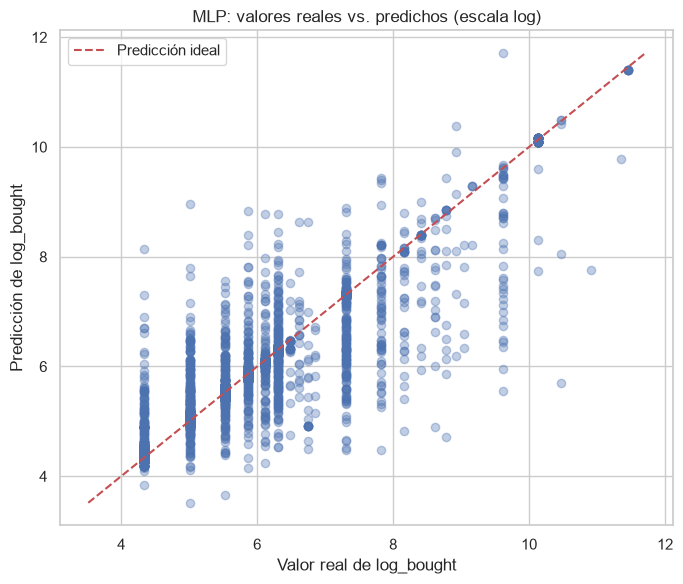

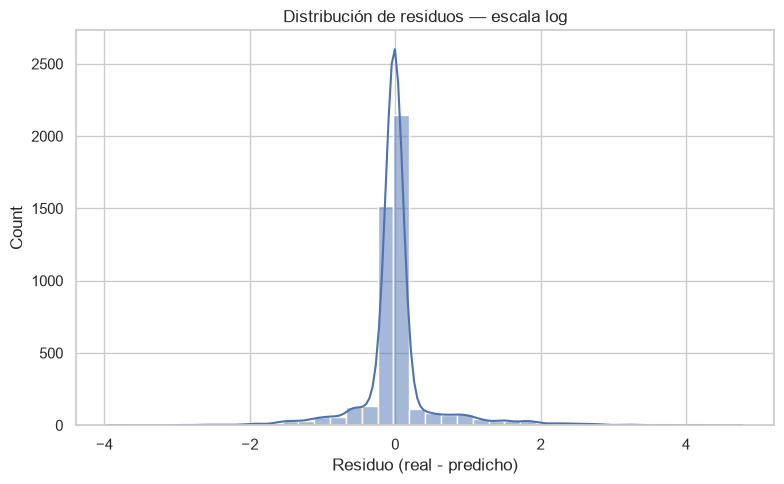

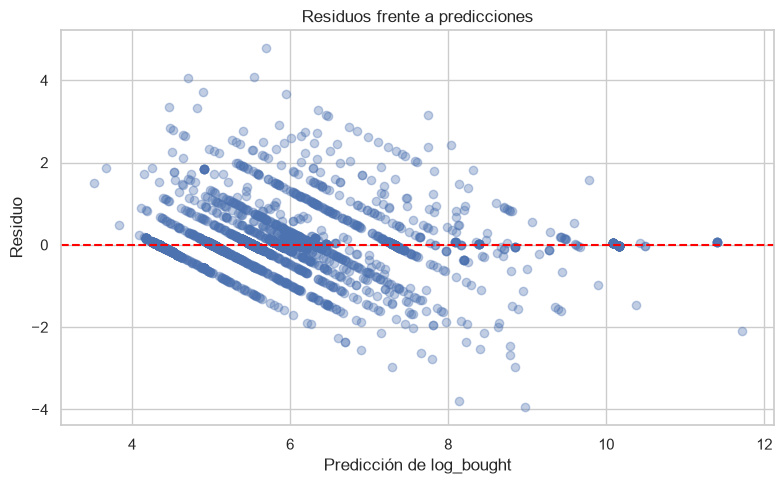

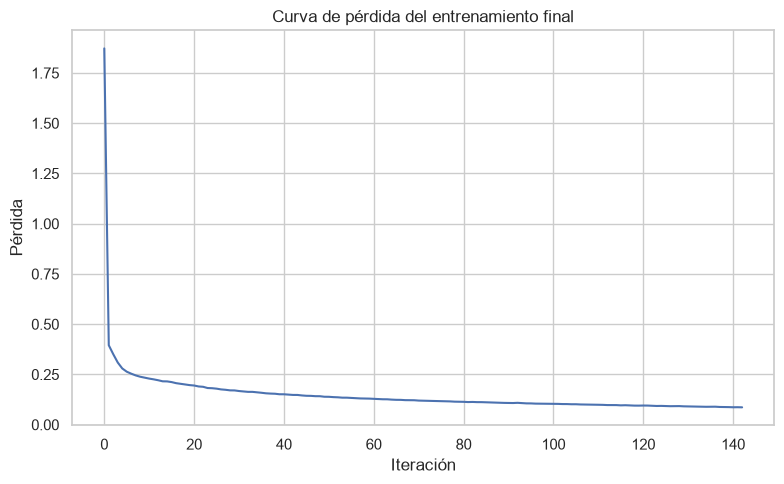

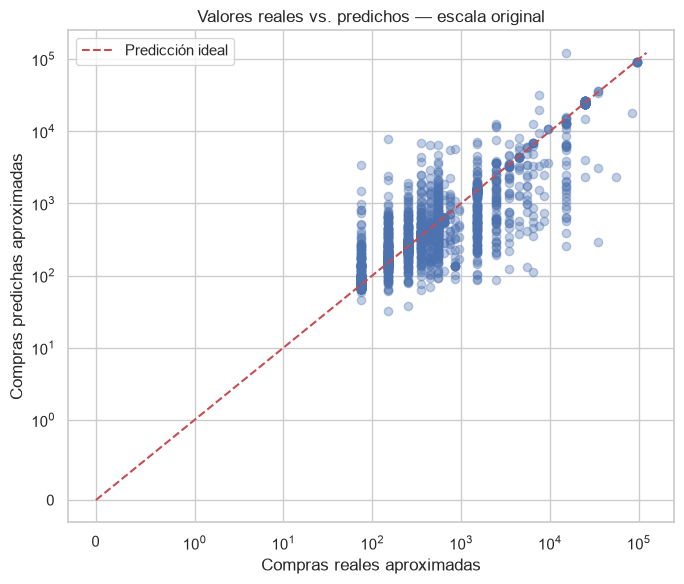

In [46]:
# Valores reales frente a predichos (escala log)
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred_log, alpha=0.35)
lims = [
    min(float(np.min(y_test)), float(np.min(y_pred_log))),
    max(float(np.max(y_test)), float(np.max(y_pred_log)))
]
plt.plot(lims, lims, "r--", label="Predicción ideal")
plt.xlabel("Valor real de log_bought")
plt.ylabel("Predicción de log_bought")
plt.title("MLP: valores reales vs. predichos (escala log)")
plt.legend()
plt.tight_layout()
plt.show()

# Residuos en escala log
residuals = y_test.to_numpy() - y_pred_log
plt.figure(figsize=(8, 5))
sns.histplot(residuals, bins=40, kde=True)
plt.xlabel("Residuo (real - predicho)")
plt.title("Distribución de residuos — escala log")
plt.tight_layout()
plt.show()

# Residuos frente a predicción
plt.figure(figsize=(8, 5))
plt.scatter(y_pred_log, residuals, alpha=0.35)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicción de log_bought")
plt.ylabel("Residuo")
plt.title("Residuos frente a predicciones")
plt.tight_layout()
plt.show()

# Curva de pérdida de la MLP final
final_model = final_pipeline.named_steps["model"]
plt.figure(figsize=(8, 5))
plt.plot(final_model.loss_curve_)
plt.xlabel("Iteración")
plt.ylabel("Pérdida")
plt.title("Curva de pérdida del entrenamiento final")
plt.tight_layout()
plt.show()

# Escala original: comparación en log-log para permitir ver la cola
plt.figure(figsize=(7, 6))
plt.scatter(y_test_original, y_pred_original, alpha=0.35)
max_value = max(float(np.max(y_test_original)), float(np.max(y_pred_original)), 1.0)
plt.plot([0, max_value], [0, max_value], "r--", label="Predicción ideal")
plt.xscale("symlog", linthresh=1)
plt.yscale("symlog", linthresh=1)
plt.xlabel("Compras reales aproximadas")
plt.ylabel("Compras predichas aproximadas")
plt.title("Valores reales vs. predichos — escala original")
plt.legend()
plt.tight_layout()
plt.show()

## Análisis e interpretación

La MLP aprende relaciones no lineales mediante la composición de capas densas y funciones de activación. A diferencia de un modelo lineal, puede representar interacciones complejas entre precio, reputación, descuentos y disponibilidad. Sin embargo, esa flexibilidad también aumenta el riesgo de sobreajuste y hace que la interpretación directa de los pesos sea menos sencilla.

Al interpretar los resultados se recomienda revisar:

1. **RMSE frente a MAE:** una diferencia grande puede indicar errores elevados en algunos productos.
2. **R²:** indica qué proporción de variabilidad explica el modelo respecto a la referencia de la media; puede ser negativo si el modelo generaliza mal.
3. **RMSLE:** resume el error relativo en la escala original, con menor peso relativo para diferencias absolutas grandes en productos de alto volumen.
4. **Residuos:** una estructura visible o dispersión creciente puede revelar sesgo o heterocedasticidad.
5. **Convergencia:** una curva de pérdida que sigue descendiendo al llegar al máximo de iteraciones puede sugerir que se necesita ajustar `max_iter` o la tasa de aprendizaje.

La transformación inversa `expm1` no convierte necesariamente una predicción media en escala logarítmica en la media aritmética de las compras. Por tanto, las predicciones en unidades originales deben entenderse como estimaciones retransformadas, no como medias corregidas automáticamente.

In [47]:
print("Resumen del experimento:")
print("Configuración seleccionada:", selected_name)
print("Hiperparámetros finales:")
display(pd.Series(final_model.get_params(), name="Valor").to_frame())

print("\\nMétricas en escala log:")
display(pd.Series(metrics_log, name="Valor").to_frame())

print("\\nMétricas en escala original:")
display(pd.Series(metrics_original, name="Valor").to_frame())

print("\\nIteraciones del último ajuste:", final_model.n_iter_)
print("¿Alcanzó max_iter?:", final_model.n_iter_ >= final_model.max_iter)

Resumen del experimento:
Configuración seleccionada: MLP optimizada
Hiperparámetros finales:


,Valor
activation,tanh
alpha,0.0001
batch_size,auto
beta_1,0.9
beta_2,0.999
early_stopping,True
epsilon,0.0
hidden_layer_sizes,"(128, 64, 32)"
learning_rate,constant
learning_rate_init,0.001


\nMétricas en escala log:


,Valor
MAE,0.248130
RMSE,0.539366
R2,0.795015


\nMétricas en escala original:


,Valor
MAE,351.390689
RMSE,2498.768837
R2,0.772780
RMSLE,0.539366


\nIteraciones del último ajuste: 143
¿Alcanzó max_iter?: False


## Exportación de resultados

Se guardan el pipeline final completo (incluyendo preprocesamiento), métricas, predicciones de prueba, mejores hiperparámetros, tabla de validación cruzada, curva de pérdida y tiempos. También se conserva el archivo de índices de partición cuando fue generado en este notebook.

El archivo de predicciones incluye tanto los valores logarítmicos como los valores retransformados a la escala aproximada de compras.

In [48]:
# Predicciones del conjunto de prueba
predictions_df = pd.DataFrame({
    "row_index": df.index[test_idx],
    "y_true_log": y_test.to_numpy(),
    "y_pred_log": y_pred_log,
    "y_true_original": y_test_original,
    "y_pred_original": y_pred_original,
    "residual_log": residuals,
})
predictions_df.to_csv(RESULTS_DIR / "test_predictions.csv", index=False)

# Métricas y configuración
metrics_payload = {
    "model": "MLPRegressor",
    "selected_candidate": selected_name,
    "target": TARGET,
    "dataset": str(DATA_PATH),
    "random_state": RANDOM_STATE,
    "n_train": int(len(train_idx)),
    "n_validation": int(len(val_idx)),
    "n_test": int(len(test_idx)),
    "metrics_log_scale": {k: float(v) for k, v in metrics_log.items()},
    "metrics_original_scale": {k: float(v) for k, v in metrics_original.items()},
    "training_seconds_final": float(final_fit_seconds),
    "prediction_seconds_test": float(prediction_seconds),
    "search_seconds": float(search_seconds),
    "iterations_final": int(final_model.n_iter_),
    "max_iter": int(final_model.max_iter),
}

with open(RESULTS_DIR / "metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics_payload, f, indent=2, ensure_ascii=False)

with open(RESULTS_DIR / "best_hyperparameters.json", "w", encoding="utf-8") as f:
    json.dump(random_search.best_params_, f, indent=2, ensure_ascii=False)

cv_results = pd.DataFrame(random_search.cv_results_)
cv_results.to_csv(RESULTS_DIR / "hyperparameter_search.csv", index=False)

loss_df = pd.DataFrame({
    "iteration": np.arange(1, len(final_model.loss_curve_) + 1),
    "loss": final_model.loss_curve_
})
loss_df.to_csv(RESULTS_DIR / "loss_curve.csv", index=False)

joblib.dump(final_pipeline, RESULTS_DIR / "mlp_final.joblib")

print("Resultados exportados en:", RESULTS_DIR.resolve())
for file in sorted(RESULTS_DIR.iterdir()):
    print("-", file.name)

Resultados exportados en: C:\Users\Juan Mona\Documents\Repositories\ProductScope-ML\Modelos entrenados\Models_Results\mlp
- best_hyperparameters.json
- hyperparameter_search.csv
- loss_curve.csv
- metrics.json
- mlp_final.joblib
- split_indices.json
- test_predictions.csv
